# 02. 리뷰 데이터 탐색

`data/raw/olist_order_reviews_dataset.csv`를 중심으로 LLM 분류 전에 리뷰 데이터를 살펴본다.

1. 키 무결성 확인
2. 점수별 분포
3. 텍스트 길이
4. 샘플 읽기
5. LLM 분류 대상 후보별 건수

차트는 `reports/figures`에 png로 저장한다. 원본 파일은 읽기만 한다.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 200)


def find_project_root(start: Path) -> Path:
    """data/raw 폴더가 있는 프로젝트 루트를 찾는다."""
    for path in [start, *start.parents]:
        if (path / "data" / "raw").is_dir():
            return path
    raise FileNotFoundError("프로젝트 루트(data/raw)를 찾을 수 없습니다.")


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 차트 스타일: 한글 폰트, 얇은 막대, 옅은 격자
plt.rcParams.update({
    "font.family": "Malgun Gothic",
    "axes.unicode_minus": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8986",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "axes.axisbelow": True,
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})
BAR_COLOR = "#2a78d6"
TEXT_COLOR = "#0b0b0b"


def save_fig(fig, filename: str) -> None:
    """차트를 reports/figures에 png로 저장한다."""
    path = FIG_DIR / filename
    fig.savefig(path)
    print(f"저장: {path.relative_to(PROJECT_ROOT)}")

## 데이터 읽기

텍스트 유무는 `review_comment_message`가 결측이 아니고, 앞뒤 공백을 제거했을 때 빈 문자열이 아닌 경우로 정의한다.

In [2]:
reviews = pd.read_csv(RAW_DIR / "olist_order_reviews_dataset.csv", encoding="utf-8")

msg = reviews["review_comment_message"].fillna("").str.strip()
reviews["has_text"] = msg.ne("")
reviews["text_len"] = msg.str.len().where(reviews["has_text"])

blank_only = reviews["review_comment_message"].notna() & ~reviews["has_text"]
print(f"전체 리뷰: {len(reviews):,}건")
print(f"텍스트 있는 리뷰: {reviews['has_text'].sum():,}건")
print(f"값은 있으나 공백뿐인 텍스트: {blank_only.sum():,}건")

전체 리뷰: 99,224건
텍스트 있는 리뷰: 40,950건
값은 있으나 공백뿐인 텍스트: 27건


## 1. 키 무결성 확인

In [3]:
review_id_dup = reviews["review_id"].duplicated(keep=False)
order_id_dup = reviews["order_id"].duplicated(keep=False)

key_check = pd.DataFrame({
    "고유값 수": [reviews["review_id"].nunique(), reviews["order_id"].nunique()],
    "중복 초과 행 수": [reviews["review_id"].duplicated().sum(), reviews["order_id"].duplicated().sum()],
    "중복에 관련된 행 수": [review_id_dup.sum(), order_id_dup.sum()],
    "중복된 키 개수": [
        reviews.loc[review_id_dup, "review_id"].nunique(),
        reviews.loc[order_id_dup, "order_id"].nunique(),
    ],
}, index=["review_id", "order_id"])
key_check

,고유값 수,중복 초과 행 수,중복에 관련된 행 수,중복된 키 개수
review_id,98410,814,1603,789
order_id,98673,551,1098,547


### review_id 중복 사례

같은 review_id가 여러 주문에 붙어 있는 경우다. 내용(점수·텍스트·날짜)이 같은지 함께 확인한다.

In [4]:
show_cols = ["review_id", "order_id", "review_score", "review_comment_message",
             "review_creation_date", "review_answer_timestamp"]

dup_review_ids = reviews.loc[review_id_dup, "review_id"].drop_duplicates().head(3)
display(reviews.loc[reviews["review_id"].isin(dup_review_ids), show_cols]
        .sort_values("review_id"))

# review_id가 같은 행끼리 점수·텍스트·날짜가 모두 같은지 확인
content_cols = ["review_score", "review_comment_title", "review_comment_message",
                "review_creation_date", "review_answer_timestamp"]
variants = (reviews.loc[review_id_dup]
            .groupby("review_id")[content_cols]
            .nunique(dropna=False)
            .max(axis=1))
print(f"중복 review_id {len(variants):,}개 중 내용이 모두 같은 것: {(variants == 1).sum():,}개")
print(f"중복 review_id당 주문 수 분포:")
print(reviews.loc[review_id_dup].groupby("review_id").size().value_counts().sort_index().to_string())

,review_id,order_id,review_score,review_comment_message,review_creation_date,review_answer_timestamp
200,28642ce6250b94cc72bc85960aec6c62,e239d280236cdd3c40cb2c033f681d1c,5,NaN,2018-03-25 00:00:00,2018-03-25 21:03:02
58385,28642ce6250b94cc72bc85960aec6c62,bc42a955f289870d5789e6e437206300,5,NaN,2018-03-25 00:00:00,2018-03-25 21:03:02
344,a0a641414ff718ca079b3967ef5c2495,169d7e0fd71d624d306f132acd791cbe,5,NaN,2018-03-04 00:00:00,2018-03-06 20:12:53
27356,a0a641414ff718ca079b3967ef5c2495,4e93b736e8d687bca088c6ee496437e8,5,NaN,2018-03-04 00:00:00,2018-03-06 20:12:53
346,f4d74b17cd63ee35efa82cd2567de911,f269e83a82f64baa3de97c2ebf3358f6,3,"A embalagem deixou a desejar, por pouco o produto não foi danificado, a caixa estava toda amassada.",2018-01-12 00:00:00,2018-01-13 18:46:10
90298,f4d74b17cd63ee35efa82cd2567de911,a60c9bf6dcdd39e9f1c10ae5ad77c24d,3,"A embalagem deixou a desejar, por pouco o produto não foi danificado, a caixa estava toda amassada.",2018-01-12 00:00:00,2018-01-13 18:46:10


중복 review_id 789개 중 내용이 모두 같은 것: 789개
중복 review_id당 주문 수 분포:
2    764
3     25


### order_id 중복 사례

한 주문에 리뷰가 여러 개 달린 경우다. 점수가 서로 다른지도 확인한다.

In [5]:
reviews_per_order = reviews.groupby("order_id").size()
print("주문당 리뷰 수 분포:")
print(reviews_per_order.value_counts().sort_index().to_string())

multi = reviews.loc[order_id_dup]
score_nunique = multi.groupby("order_id")["review_score"].nunique()
print(f"\n리뷰가 여러 개인 주문 {len(score_nunique):,}개 중 점수가 서로 다른 주문: {(score_nunique > 1).sum():,}개")

# 대표 사례: 점수가 다른 주문 3개
sample_orders = score_nunique[score_nunique > 1].index[:3]
display(reviews.loc[reviews["order_id"].isin(sample_orders), show_cols]
        .sort_values(["order_id", "review_creation_date"]))

주문당 리뷰 수 분포:
1    98126
2      543
3        4

리뷰가 여러 개인 주문 547개 중 점수가 서로 다른 주문: 202개


,review_id,order_id,review_score,review_comment_message,review_creation_date,review_answer_timestamp
22779,ab30810c29da5da8045216f0f62652a2,013056cfe49763c6f66bda03396c5ee3,5,NaN,2018-02-22 00:00:00,2018-02-23 12:12:30
68633,73413b847f63e02bc752b364f6d05ee9,013056cfe49763c6f66bda03396c5ee3,4,NaN,2018-03-04 00:00:00,2018-03-05 17:02:00
89888,0c8e7347f1cdd2aede37371543e3d163,02355020fd0a40a0d56df9f6ff060413,3,UM DOS PRODUTOS (ENTREGA02) COMPRADOS NESTE PEDIDO NAO RECEBI AINDA E OUTRO (ENTREGA01) RECEBI EMAIL QUE ESTA COM DIFICULDADES NA ENTREGA E NÃO TIVE MAIS NOTICIAS,2018-03-21 00:00:00,2018-03-22 01:32:08
17582,017f0e1ea6386de662cbeba299c59ad1,02355020fd0a40a0d56df9f6ff060413,1,ja reclamei varias vezes e ate hoje não sei onde foi parar o produto que comprei. quero cancelar esta compra e quero meu dinheiro de volta.,2018-03-29 00:00:00,2018-03-30 03:16:19
37911,04d945e95c788a3aa1ffbee42105637b,029863af4b968de1e5d6a82782e662f5,5,NaN,2017-07-14 00:00:00,2017-07-17 13:58:06
55137,61fe4e7d1ae801bbe169eb67b86c6eda,029863af4b968de1e5d6a82782e662f5,4,NaN,2017-07-19 00:00:00,2017-07-20 12:06:11


## 2. 점수별 분포

In [6]:
score_stats = reviews.groupby("review_score").agg(
    리뷰수=("review_id", "size"),
    텍스트작성수=("has_text", "sum"),
)
score_stats["리뷰비율(%)"] = (score_stats["리뷰수"] / score_stats["리뷰수"].sum() * 100).round(2)
score_stats["텍스트작성률(%)"] = (score_stats["텍스트작성수"] / score_stats["리뷰수"] * 100).round(2)
score_stats["텍스트리뷰중비율(%)"] = (score_stats["텍스트작성수"] / score_stats["텍스트작성수"].sum() * 100).round(2)
score_stats = score_stats[["리뷰수", "리뷰비율(%)", "텍스트작성수", "텍스트작성률(%)", "텍스트리뷰중비율(%)"]]

total_row = pd.DataFrame({
    "리뷰수": [score_stats["리뷰수"].sum()],
    "리뷰비율(%)": [100.0],
    "텍스트작성수": [score_stats["텍스트작성수"].sum()],
    "텍스트작성률(%)": [round(score_stats["텍스트작성수"].sum() / score_stats["리뷰수"].sum() * 100, 2)],
    "텍스트리뷰중비율(%)": [100.0],
}, index=pd.Index(["전체"], name="review_score"))
display(pd.concat([score_stats, total_row]))

,리뷰수,리뷰비율(%),텍스트작성수,텍스트작성률(%),텍스트리뷰중비율(%)
review_score,,,,,
1,11424,11.51,8744,76.54,21.35
2,3151,3.18,2145,68.07,5.24
3,8179,8.24,3556,43.48,8.68
4,19142,19.29,5970,31.19,14.58
5,57328,57.78,20535,35.82,50.15
전체,99224,100.00,40950,41.27,100.00


저장: reports\figures\02_review_score_distribution.png


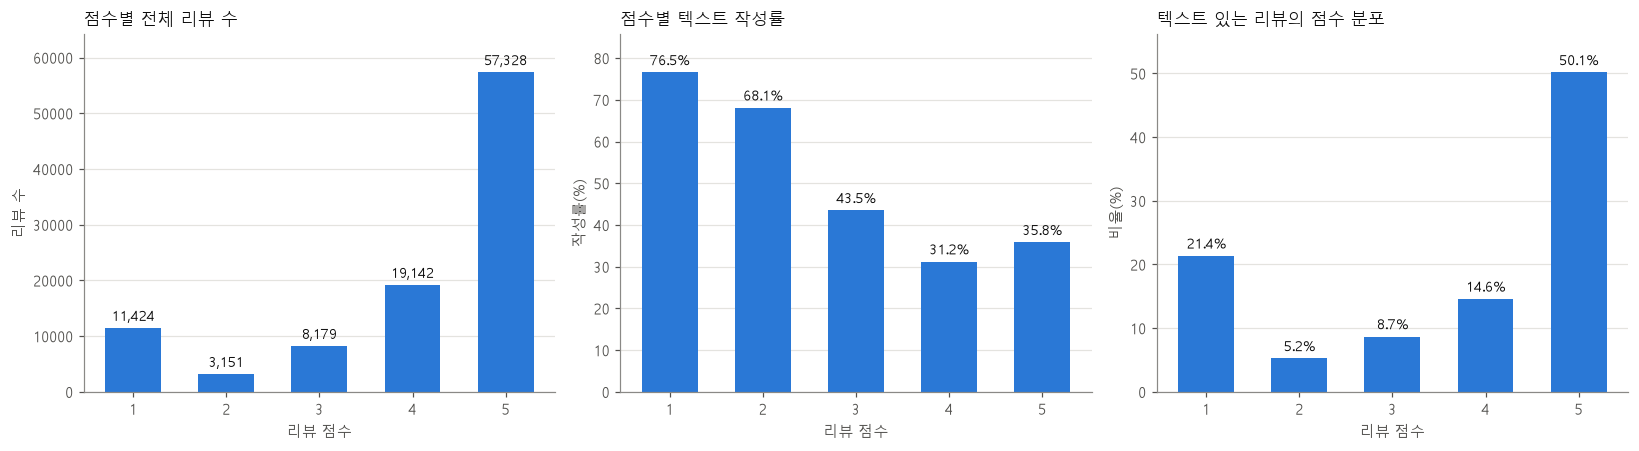

In [7]:
def bar_with_labels(ax, x, y, fmt: str, title: str, ylabel: str) -> None:
    """막대 차트를 그리고 막대 위에 값을 표시한다."""
    bars = ax.bar(x, y, color=BAR_COLOR, width=0.6)
    ax.bar_label(bars, labels=[fmt.format(v) for v in y], padding=3, color=TEXT_COLOR, fontsize=9)
    ax.set_title(title, loc="left", fontsize=11, color=TEXT_COLOR)
    ax.set_xlabel("리뷰 점수")
    ax.set_ylabel(ylabel)
    ax.set_xticks(list(x))
    ax.margins(y=0.12)


x = score_stats.index
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
bar_with_labels(axes[0], x, score_stats["리뷰수"], "{:,.0f}", "점수별 전체 리뷰 수", "리뷰 수")
bar_with_labels(axes[1], x, score_stats["텍스트작성률(%)"], "{:.1f}%", "점수별 텍스트 작성률", "작성률(%)")
bar_with_labels(axes[2], x, score_stats["텍스트리뷰중비율(%)"], "{:.1f}%", "텍스트 있는 리뷰의 점수 분포", "비율(%)")
fig.tight_layout()
save_fig(fig, "02_review_score_distribution.png")
plt.show()

## 3. 텍스트 길이

글자 수는 앞뒤 공백을 제거한 텍스트 기준이다.

In [8]:
text_reviews = reviews.loc[reviews["has_text"]].copy()
lengths = text_reviews["text_len"]

length_stats = pd.Series({
    "건수": len(lengths),
    "평균": lengths.mean(),
    "중앙값": lengths.median(),
    "90백분위수": lengths.quantile(0.90),
    "99백분위수": lengths.quantile(0.99),
    "최소": lengths.min(),
    "최대": lengths.max(),
}).round(1)
display(length_stats.to_frame("글자 수"))

len_by_score = text_reviews.groupby("review_score")["text_len"].agg(
    건수="size", 평균="mean", 중앙값="median"
).round(1)
display(len_by_score)

,글자 수
건수,40950.0
평균,68.4
중앙값,53.0
90백분위수,160.0
99백분위수,200.0
최소,1.0
최대,208.0


,건수,평균,중앙값
review_score,,,
1,8744,99.7,89.0
2,2145,96.6,87.0
3,3556,83.1,70.0
4,5970,61.5,46.0
5,20535,51.6,42.0


저장: reports\figures\02_review_text_length.png


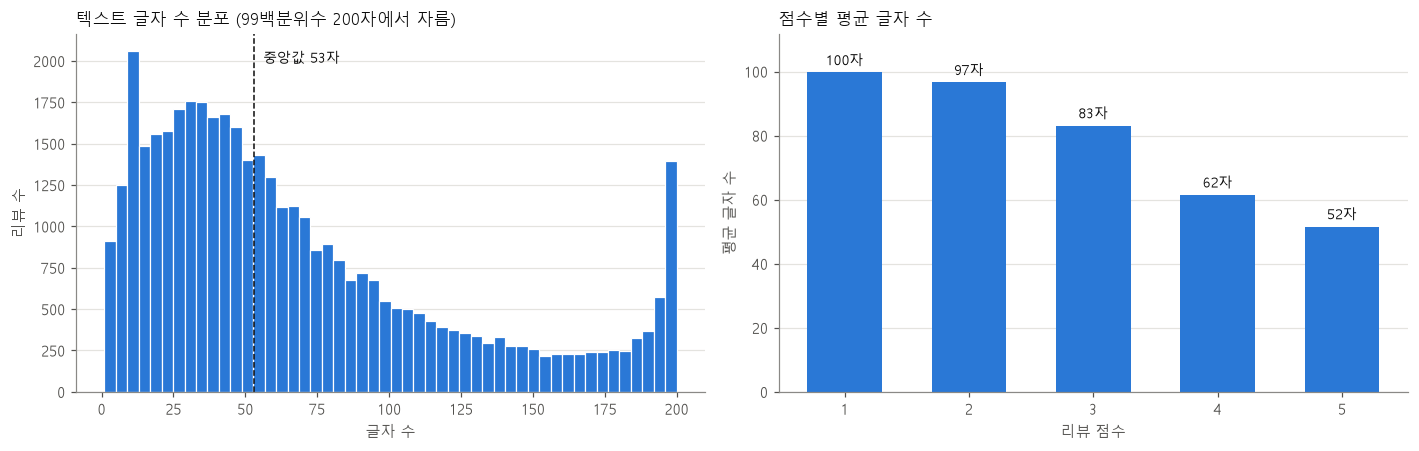

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

p99 = lengths.quantile(0.99)
axes[0].hist(lengths.clip(upper=p99), bins=50, color=BAR_COLOR, edgecolor="white", linewidth=0.8)
axes[0].axvline(lengths.median(), color=TEXT_COLOR, linewidth=1, linestyle="--")
axes[0].annotate(f"중앙값 {lengths.median():.0f}자", xy=(lengths.median(), axes[0].get_ylim()[1] * 0.92),
                 xytext=(6, 0), textcoords="offset points", color=TEXT_COLOR, fontsize=9)
axes[0].set_title(f"텍스트 글자 수 분포 (99백분위수 {p99:.0f}자에서 자름)", loc="left", fontsize=11, color=TEXT_COLOR)
axes[0].set_xlabel("글자 수")
axes[0].set_ylabel("리뷰 수")

bar_with_labels(axes[1], len_by_score.index, len_by_score["평균"], "{:.0f}자", "점수별 평균 글자 수", "평균 글자 수")
fig.tight_layout()
save_fig(fig, "02_review_text_length.png")
plt.show()

### 너무 짧은 리뷰 (5자 이하)

In [10]:
SHORT_LEN = 5
short = text_reviews.loc[text_reviews["text_len"] <= SHORT_LEN]
print(f"{SHORT_LEN}자 이하 리뷰: {len(short):,}건 (텍스트 있는 리뷰의 {len(short) / len(text_reviews) * 100:.2f}%)")

print("\n점수별 건수:")
print(short["review_score"].value_counts().sort_index().to_string())

print("\n자주 나오는 짧은 텍스트 상위 15개:")
display(short["review_comment_message"].str.strip().value_counts().head(15).to_frame("건수"))

5자 이하 리뷰: 1,470건 (텍스트 있는 리뷰의 3.59%)

점수별 건수:
review_score
1     41
2     24
3    142
4    315
5    948

자주 나오는 짧은 텍스트 상위 15개:


,건수
review_comment_message,
Bom,215
Ótimo,158
bom,111
otimo,108
Otimo,107
Ok,78
ok,58
Boa,55
.,52


## 4. 샘플 읽기

점수 1, 3, 5에서 텍스트가 있는 리뷰를 각각 무작위 5건씩 뽑는다 (`random_state=42`).

In [11]:
def show_samples(score: int, n: int = 5) -> None:
    """특정 점수의 텍스트 리뷰를 무작위로 n건 출력한다."""
    sample = text_reviews.loc[text_reviews["review_score"] == score].sample(n=n, random_state=42)
    print(f"===== {score}점 =====")
    for i, row in enumerate(sample.itertuples(), start=1):
        title = row.review_comment_title if pd.notna(row.review_comment_title) else "-"
        text = " ".join(row.review_comment_message.split())
        print(f"[{i}] 제목: {title}")
        print(f"    본문: {text}")
    print()


for score in [1, 3, 5]:
    show_samples(score)

===== 1점 =====
[1] 제목: N foi entregue ainda 
    본문: Demora de entrega
[2] 제목: -
    본문: Depois que fiz a compra, passou 30 dias para a loja me informar que não tem mais a mercadoria
[3] 제목: -
    본문: ainda não entregaram meu produto, apenas o outros que avia comprado junto, mas o cabo HDMI NÃO foi entregue
[4] 제목: -
    본문: Não estou satisfeita, pois ainda não recebi o produto.
[5] 제목: -
    본문: Até hoje não recebi meu produto. Vou fazer uma reclamação no Procon e procurar meus direitos.

===== 3점 =====
[1] 제목: -
    본문: O tecido não é bom.
[2] 제목: -
    본문: O produto foi entregue, porém a pelicula do celular veio no tamanho incorreto, impedindo o uso. Ou seja, usei apenas a capinha, paguei total de 100% para usar 50%.
[3] 제목: Produto errado
    본문: Não veio o mesmo produto referente à foto no momento compra !
[4] 제목: Preços bons
    본문: Tá demorando a entrega
[5] 제목: -
    본문: Boa noite. Na descrição está como 94cm, achei que seria 94 de largura e não de altura. Quero trocar o produt

## 5. LLM 분류 대상 후보별 건수

- 후보 A: 텍스트 있는 전체 리뷰
- 후보 B: 텍스트 있는 1~2점 리뷰
- 후보 C: 텍스트 있는 1~3점 리뷰

행 기준 건수와 함께, 중복 review_id를 하나로 셌을 때의 건수도 표시한다.

In [12]:
candidates = {
    "A: 텍스트 있는 전체": text_reviews,
    "B: 텍스트 있는 1~2점": text_reviews.loc[text_reviews["review_score"] <= 2],
    "C: 텍스트 있는 1~3점": text_reviews.loc[text_reviews["review_score"] <= 3],
}

candidate_table = pd.DataFrame([
    {
        "후보": name,
        "건수(행)": len(df),
        "건수(고유 review_id)": df["review_id"].nunique(),
        "총 글자 수": int(df["text_len"].sum()),
        "평균 글자 수": round(df["text_len"].mean(), 1),
        "5자 이하 건수": int((df["text_len"] <= SHORT_LEN).sum()),
    }
    for name, df in candidates.items()
]).set_index("후보")
candidate_table

,건수(행),건수(고유 review_id),총 글자 수,평균 글자 수,5자 이하 건수
후보,,,,,
A: 텍스트 있는 전체,40950,40641,2800913,68.4,1470
B: 텍스트 있는 1~2점,10889,10758,1078644,99.1,65
C: 텍스트 있는 1~3점,14445,14286,1374035,95.1,207
